# MobileNetV2 Retinal Image Validator Evaluation

## Objective

Evaluate the binary retinal image validation model
on independent test images and determine an appropriate
acceptance threshold.

## Class Mapping

0 - Non-Retinal Image
1 - Retinal Fundus Image

## Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC-AUC
- False Acceptance Rate
- False Rejection Rate

In [1]:
import os
import json

from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "ml-model" / "dataset").exists()
)

ML_ROOT = PROJECT_ROOT / "ml-model"

VALIDATOR_DIR = (
    ML_ROOT / "dataset" / "retinal_validation"
)

METADATA_DIR = VALIDATOR_DIR / "metadata"

HARD_NEGATIVE_DIR = VALIDATOR_DIR / "hard_negatives"

MODEL_PATH = (
    ML_ROOT
    / "saved_models"
    / "retinal_validator.keras"
)

RESULTS_DIR = ML_ROOT / "evaluation" / "retinal_validator"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGE_SIZE = (224, 224)

BATCH_SIZE = 16

assert MODEL_PATH.exists()

print("Project Root:", PROJECT_ROOT)
print("Model Path:", MODEL_PATH)
print("Results Directory:", RESULTS_DIR)

Project Root: d:\AI-Powered-Diabetic-Retinopathy-System
Model Path: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\saved_models\retinal_validator.keras
Results Directory: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\evaluation\retinal_validator


In [3]:
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "ml-model" / "dataset").exists()
)

ML_ROOT = PROJECT_ROOT / "ml-model"

VALIDATOR_DIR = (
    ML_ROOT / "dataset" / "retinal_validation"
)

METADATA_DIR = VALIDATOR_DIR / "metadata"

HARD_NEGATIVE_DIR = VALIDATOR_DIR / "hard_negatives"

MODEL_PATH = (
    ML_ROOT
    / "saved_models"
    / "retinal_validator.keras"
)

RESULTS_DIR = ML_ROOT / "evaluation" / "retinal_validator"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGE_SIZE = (224, 224)

BATCH_SIZE = 16

assert MODEL_PATH.exists()

print("Project Root:", PROJECT_ROOT)
print("Model Path:", MODEL_PATH)
print("Results Directory:", RESULTS_DIR)

Project Root: d:\AI-Powered-Diabetic-Retinopathy-System
Model Path: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\saved_models\retinal_validator.keras
Results Directory: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\evaluation\retinal_validator


In [4]:
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Retinal validator loaded successfully.")

print("Input Shape:", model.input_shape)

print("Output Shape:", model.output_shape)

print("Total Parameters:", model.count_params())

Retinal validator loaded successfully.
Input Shape: (None, 224, 224, 3)
Output Shape: (None, 1)
Total Parameters: 2422081


In [5]:
def load_split(split_name):

    df = pd.read_csv(
        METADATA_DIR / f"{split_name}.csv"
    )

    df["image_path"] = df["image_path"].apply(
        lambda p: str(PROJECT_ROOT / p)
    )

    hard_negative_path = (
        HARD_NEGATIVE_DIR / split_name
    )

    records = []

    valid_extensions = {
        ".jpg", ".jpeg", ".png"
    }

    if hard_negative_path.exists():

        for path in sorted(
            hard_negative_path.rglob("*")
        ):

            if (
                path.is_file()
                and path.suffix.lower()
                in valid_extensions
            ):

                records.append({
                    "image_path": str(path),
                    "label": 0,
                    "class_name": "non_retinal",
                    "source": "hard_negative"
                })

    if records:

        df = pd.concat(
            [df, pd.DataFrame(records)],
            ignore_index=True
        )

    assert df["image_path"].apply(
        os.path.isfile
    ).all()

    assert df["image_path"].is_unique

    return df.reset_index(drop=True)


val_df = load_split("validation")

test_df = load_split("test")

assert set(val_df["image_path"]).isdisjoint(
    test_df["image_path"]
)

print("Validation Images:", len(val_df))

print("Validation Distribution:")
print(val_df["class_name"].value_counts())

print("\nTest Images:", len(test_df))

print("Test Distribution:")
print(test_df["class_name"].value_counts())

print("\nTest Sources:")
print(test_df["source"].value_counts())

Validation Images: 600
Validation Distribution:
class_name
retinal        300
non_retinal    300
Name: count, dtype: int64

Test Images: 600
Test Distribution:
class_name
retinal        300
non_retinal    300
Name: count, dtype: int64

Test Sources:
source
APTOS2019    300
CIFAR10      300
Name: count, dtype: int64


In [6]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    label = tf.cast(
        label,
        tf.float32
    )

    label = tf.reshape(label, [1])

    return image, label


def create_dataset(df):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            df["image_path"].tolist(),
            df["label"].to_numpy(dtype=np.float32)
        )
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(1)

    return dataset


val_dataset = create_dataset(val_df)

test_dataset = create_dataset(test_df)

print("Evaluation datasets created successfully.")

Evaluation datasets created successfully.


In [7]:
val_true = val_df["label"].to_numpy()

val_probabilities = model.predict(
    val_dataset,
    verbose=1
).flatten()

assert len(val_true) == len(val_probabilities)

print("\nValidation predictions generated.")

print("Minimum Score:", val_probabilities.min())

print("Maximum Score:", val_probabilities.max())

38/38 ━━━━━━━━━━━━━━━━━━━━ 17s 424ms/step

Validation predictions generated.
Minimum Score: 1.1267858e-12
Maximum Score: 1.0


In [8]:
thresholds = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.85,
    0.90,
    0.95,
    0.99
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    far = fp / (fp + tn)

    frr = fn / (fn + tp)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            val_true, predictions
        ),
        "Precision": precision_score(
            val_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            val_true,
            predictions,
            zero_division=0
        ),
        "F1_Score": f1_score(
            val_true,
            predictions,
            zero_division=0
        ),
        "FAR": far,
        "FRR": frr,
        "False_Acceptances": fp,
        "False_Rejections": fn
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(4)

,Threshold,Accuracy,Precision,Recall,F1_Score,FAR,FRR,False_Acceptances,False_Rejections
0,0.50,1.0,1.0,1.0,1.0,0.0,0.0,0,0
1,0.60,1.0,1.0,1.0,1.0,0.0,0.0,0,0
2,0.70,1.0,1.0,1.0,1.0,0.0,0.0,0,0
3,0.80,1.0,1.0,1.0,1.0,0.0,0.0,0,0
4,0.85,1.0,1.0,1.0,1.0,0.0,0.0,0,0
5,0.90,1.0,1.0,1.0,1.0,0.0,0.0,0,0
6,0.95,1.0,1.0,1.0,1.0,0.0,0.0,0,0
7,0.99,1.0,1.0,1.0,1.0,0.0,0.0,0,0


In [9]:
eligible_thresholds = threshold_df[
    threshold_df["Recall"] >= 0.95
]

if eligible_thresholds.empty:

    raise RuntimeError(
        "No threshold achieved the required "
        "validation recall."
    )

best_threshold_row = (
    eligible_thresholds
    .sort_values(
        by=["FAR", "FRR", "Threshold"],
        ascending=[True, True, False]
    )
    .iloc[0]
)

SELECTED_THRESHOLD = float(
    best_threshold_row["Threshold"]
)

print("Selected Threshold:", SELECTED_THRESHOLD)

print(
    "Validation FAR:",
    best_threshold_row["FAR"]
)

print(
    "Validation FRR:",
    best_threshold_row["FRR"]
)

Selected Threshold: 0.99
Validation FAR: 0.0
Validation FRR: 0.0


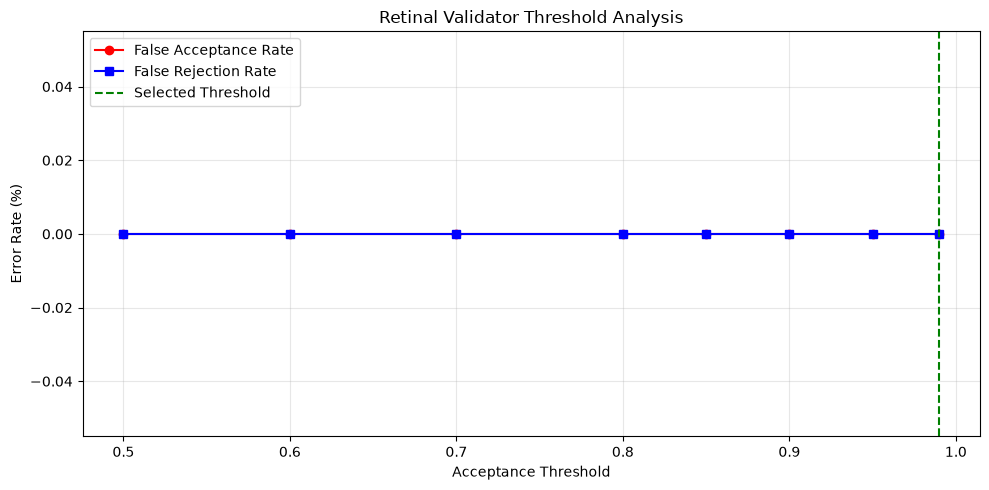

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FAR"] * 100,
    marker="o",
    label="False Acceptance Rate",
    color="red"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FRR"] * 100,
    marker="s",
    label="False Rejection Rate",
    color="blue"
)

plt.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    color="green",
    label="Selected Threshold"
)

plt.title("Retinal Validator Threshold Analysis")

plt.xlabel("Acceptance Threshold")

plt.ylabel("Error Rate (%)")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "threshold_analysis.png",
    dpi=300
)

plt.show()

In [11]:
y_true = test_df["label"].to_numpy()

y_prob = model.predict(
    test_dataset,
    verbose=1
).flatten()

y_pred = (
    y_prob >= SELECTED_THRESHOLD
).astype(int)

assert len(y_true) == len(y_pred)

print("Total Test Samples:", len(y_true))

print("Selected Threshold:", SELECTED_THRESHOLD)

print("Test predictions generated successfully.")

38/38 ━━━━━━━━━━━━━━━━━━━━ 15s 394ms/step
Total Test Samples: 600
Selected Threshold: 0.99
Test predictions generated successfully.


In [12]:
accuracy = accuracy_score(
    y_true, y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc = roc_auc_score(
    y_true, y_prob
)

print("=" * 55)

print("RETINAL VALIDATOR TEST RESULTS")

print("=" * 55)

print(f"Test Accuracy  : {accuracy * 100:.2f}%")

print(f"Test Precision : {precision * 100:.2f}%")

print(f"Test Recall    : {recall * 100:.2f}%")

print(f"Test F1-Score  : {f1 * 100:.2f}%")

print(f"ROC-AUC        : {auc:.6f}")

print("=" * 55)

RETINAL VALIDATOR TEST RESULTS
Test Accuracy  : 100.00%
Test Precision : 100.00%
Test Recall    : 100.00%
Test F1-Score  : 100.00%
ROC-AUC        : 1.000000


In [14]:
class_names = [
    "Non-Retinal",
    "Retinal"
]

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

 Non-Retinal     1.0000    1.0000    1.0000       300
     Retinal     1.0000    1.0000    1.0000       300

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600



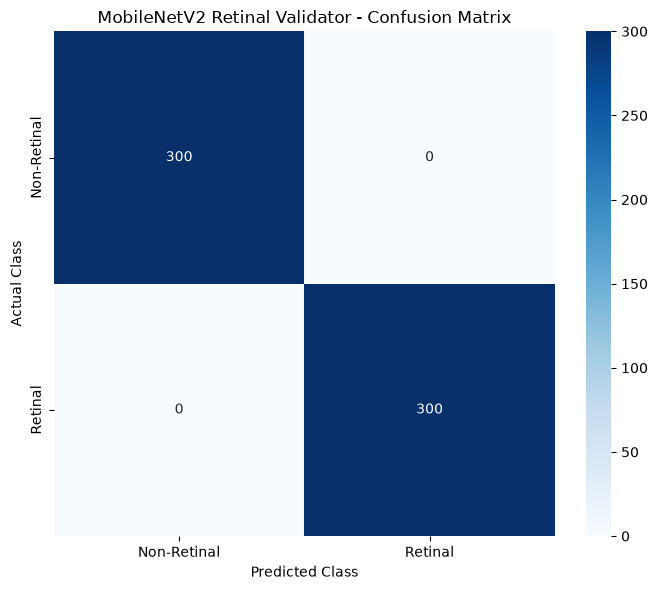

[[300   0]
 [  0 300]]


In [16]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "MobileNetV2 Retinal Validator - Confusion Matrix"
)

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

print(cm)

In [17]:
tn, fp, fn, tp = cm.ravel()

far = fp / (fp + tn)

frr = fn / (fn + tp)

print("True Negatives:", tn)

print("False Positives:", fp)

print("False Negatives:", fn)

print("True Positives:", tp)

print(f"\nFalse Acceptance Rate: {far * 100:.2f}%")

print(f"False Rejection Rate: {frr * 100:.2f}%")

True Negatives: 300
False Positives: 0
False Negatives: 0
True Positives: 300

False Acceptance Rate: 0.00%
False Rejection Rate: 0.00%


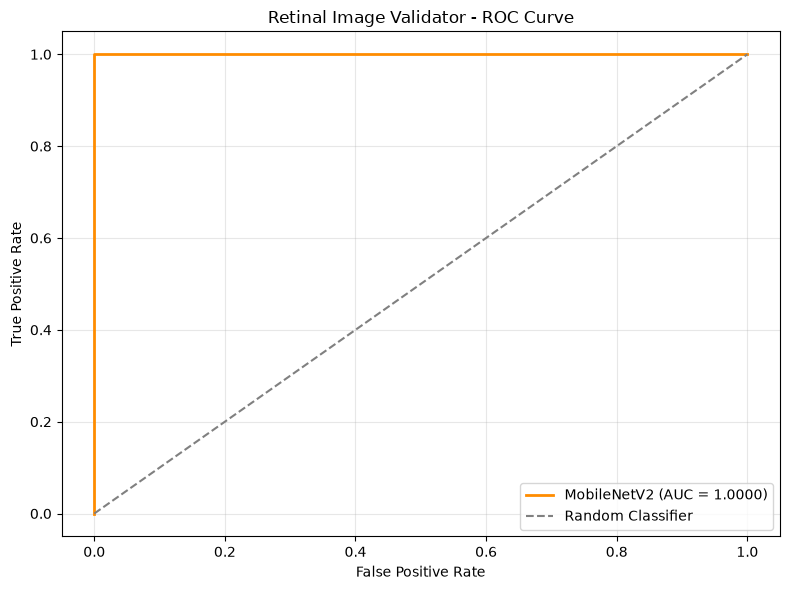

In [18]:
fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"MobileNetV2 (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Retinal Image Validator - ROC Curve")

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "roc_curve.png",
    dpi=300
)

plt.show()

In [19]:
test_results = test_df.copy()

test_results["predicted_label"] = y_pred

test_results["retinal_score"] = y_prob

test_results["correct"] = (
    test_results["label"]
    == test_results["predicted_label"]
)

source_summary = test_results.groupby(
    "source"
).agg(
    Total_Images=("correct", "size"),
    Correct_Predictions=("correct", "sum"),
    Accuracy=("correct", "mean")
)

source_summary["Incorrect_Predictions"] = (
    source_summary["Total_Images"]
    - source_summary["Correct_Predictions"]
)

source_summary["Accuracy"] *= 100

source_summary.round(4)

,Total_Images,Correct_Predictions,Accuracy,Incorrect_Predictions
source,,,,
APTOS2019,300,300,100.0,0
CIFAR10,300,300,100.0,0


In [20]:
incorrect = test_results[
    ~test_results["correct"]
]

print(
    "Incorrect Predictions:",
    len(incorrect)
)

if incorrect.empty:

    print(
        "No incorrect predictions found "
        "in this test dataset."
    )

else:

    samples = incorrect.head(12)

    fig, axes = plt.subplots(
        3, 4,
        figsize=(15, 11)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes, samples.iterrows()
    ):

        image = tf.keras.utils.load_img(
            row["image_path"]
        )

        ax.imshow(image)

        actual = class_names[int(row["label"])]

        predicted = class_names[
            int(row["predicted_label"])
        ]

        ax.set_title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Score: {row['retinal_score']:.4f}"
        )

    plt.tight_layout()

    plt.show()

Incorrect Predictions: 0
No incorrect predictions found in this test dataset.


In [30]:
def validate_retinal_image(image_path):

    image = tf.io.read_file(
        str(image_path)
    )

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.expand_dims(
        image,
        axis=0
    )

    score = float(
        model.predict(
            image,
            verbose=0
        )[0][0]
    )

    accepted = (
        score >= SELECTED_THRESHOLD
    )

    return {
        "is_retinal": accepted,
        "retinal_score": score,
        "threshold": SELECTED_THRESHOLD
    }

In [31]:
MANUAL_TEST_DIR = VALIDATOR_DIR / "manual_test"

valid_extensions = {
    ".jpg", ".jpeg", ".png"
}

manual_images = [
    path
    for path in sorted(
        MANUAL_TEST_DIR.rglob("*")
    )
    if path.is_file()
    and path.suffix.lower() in valid_extensions
]

manual_results = []

for path in manual_images:

    result = validate_retinal_image(path)

    status = (
        "Accepted"
        if result["is_retinal"]
        else "Rejected"
    )

    manual_results.append({
        "Image": path.name,
        "Retinal_Score": result["retinal_score"],
        "Status": status
    })

manual_results_df = pd.DataFrame(
    manual_results
)

manual_results_df

,Image,Retinal_Score,Status
0,cifar10_test_00320.png,3.555238e-10,Rejected
1,cifar10_test_00576.png,9.467829e-08,Rejected
2,cifar10_test_00978.png,1.546810e-09,Rejected
3,cifar10_test_01107.png,1.331240e-10,Rejected
4,cifar10_test_01218.png,1.811034e-09,Rejected
5,cifar10_test_01313.png,2.634963e-07,Rejected
6,cifar10_test_01427.png,2.685214e-12,Rejected
7,cifar10_test_01514.png,3.155248e-11,Rejected
8,cifar10_test_01619.png,2.426230e-09,Rejected
9,cifar10_test_01669.png,1.482538e-06,Rejected


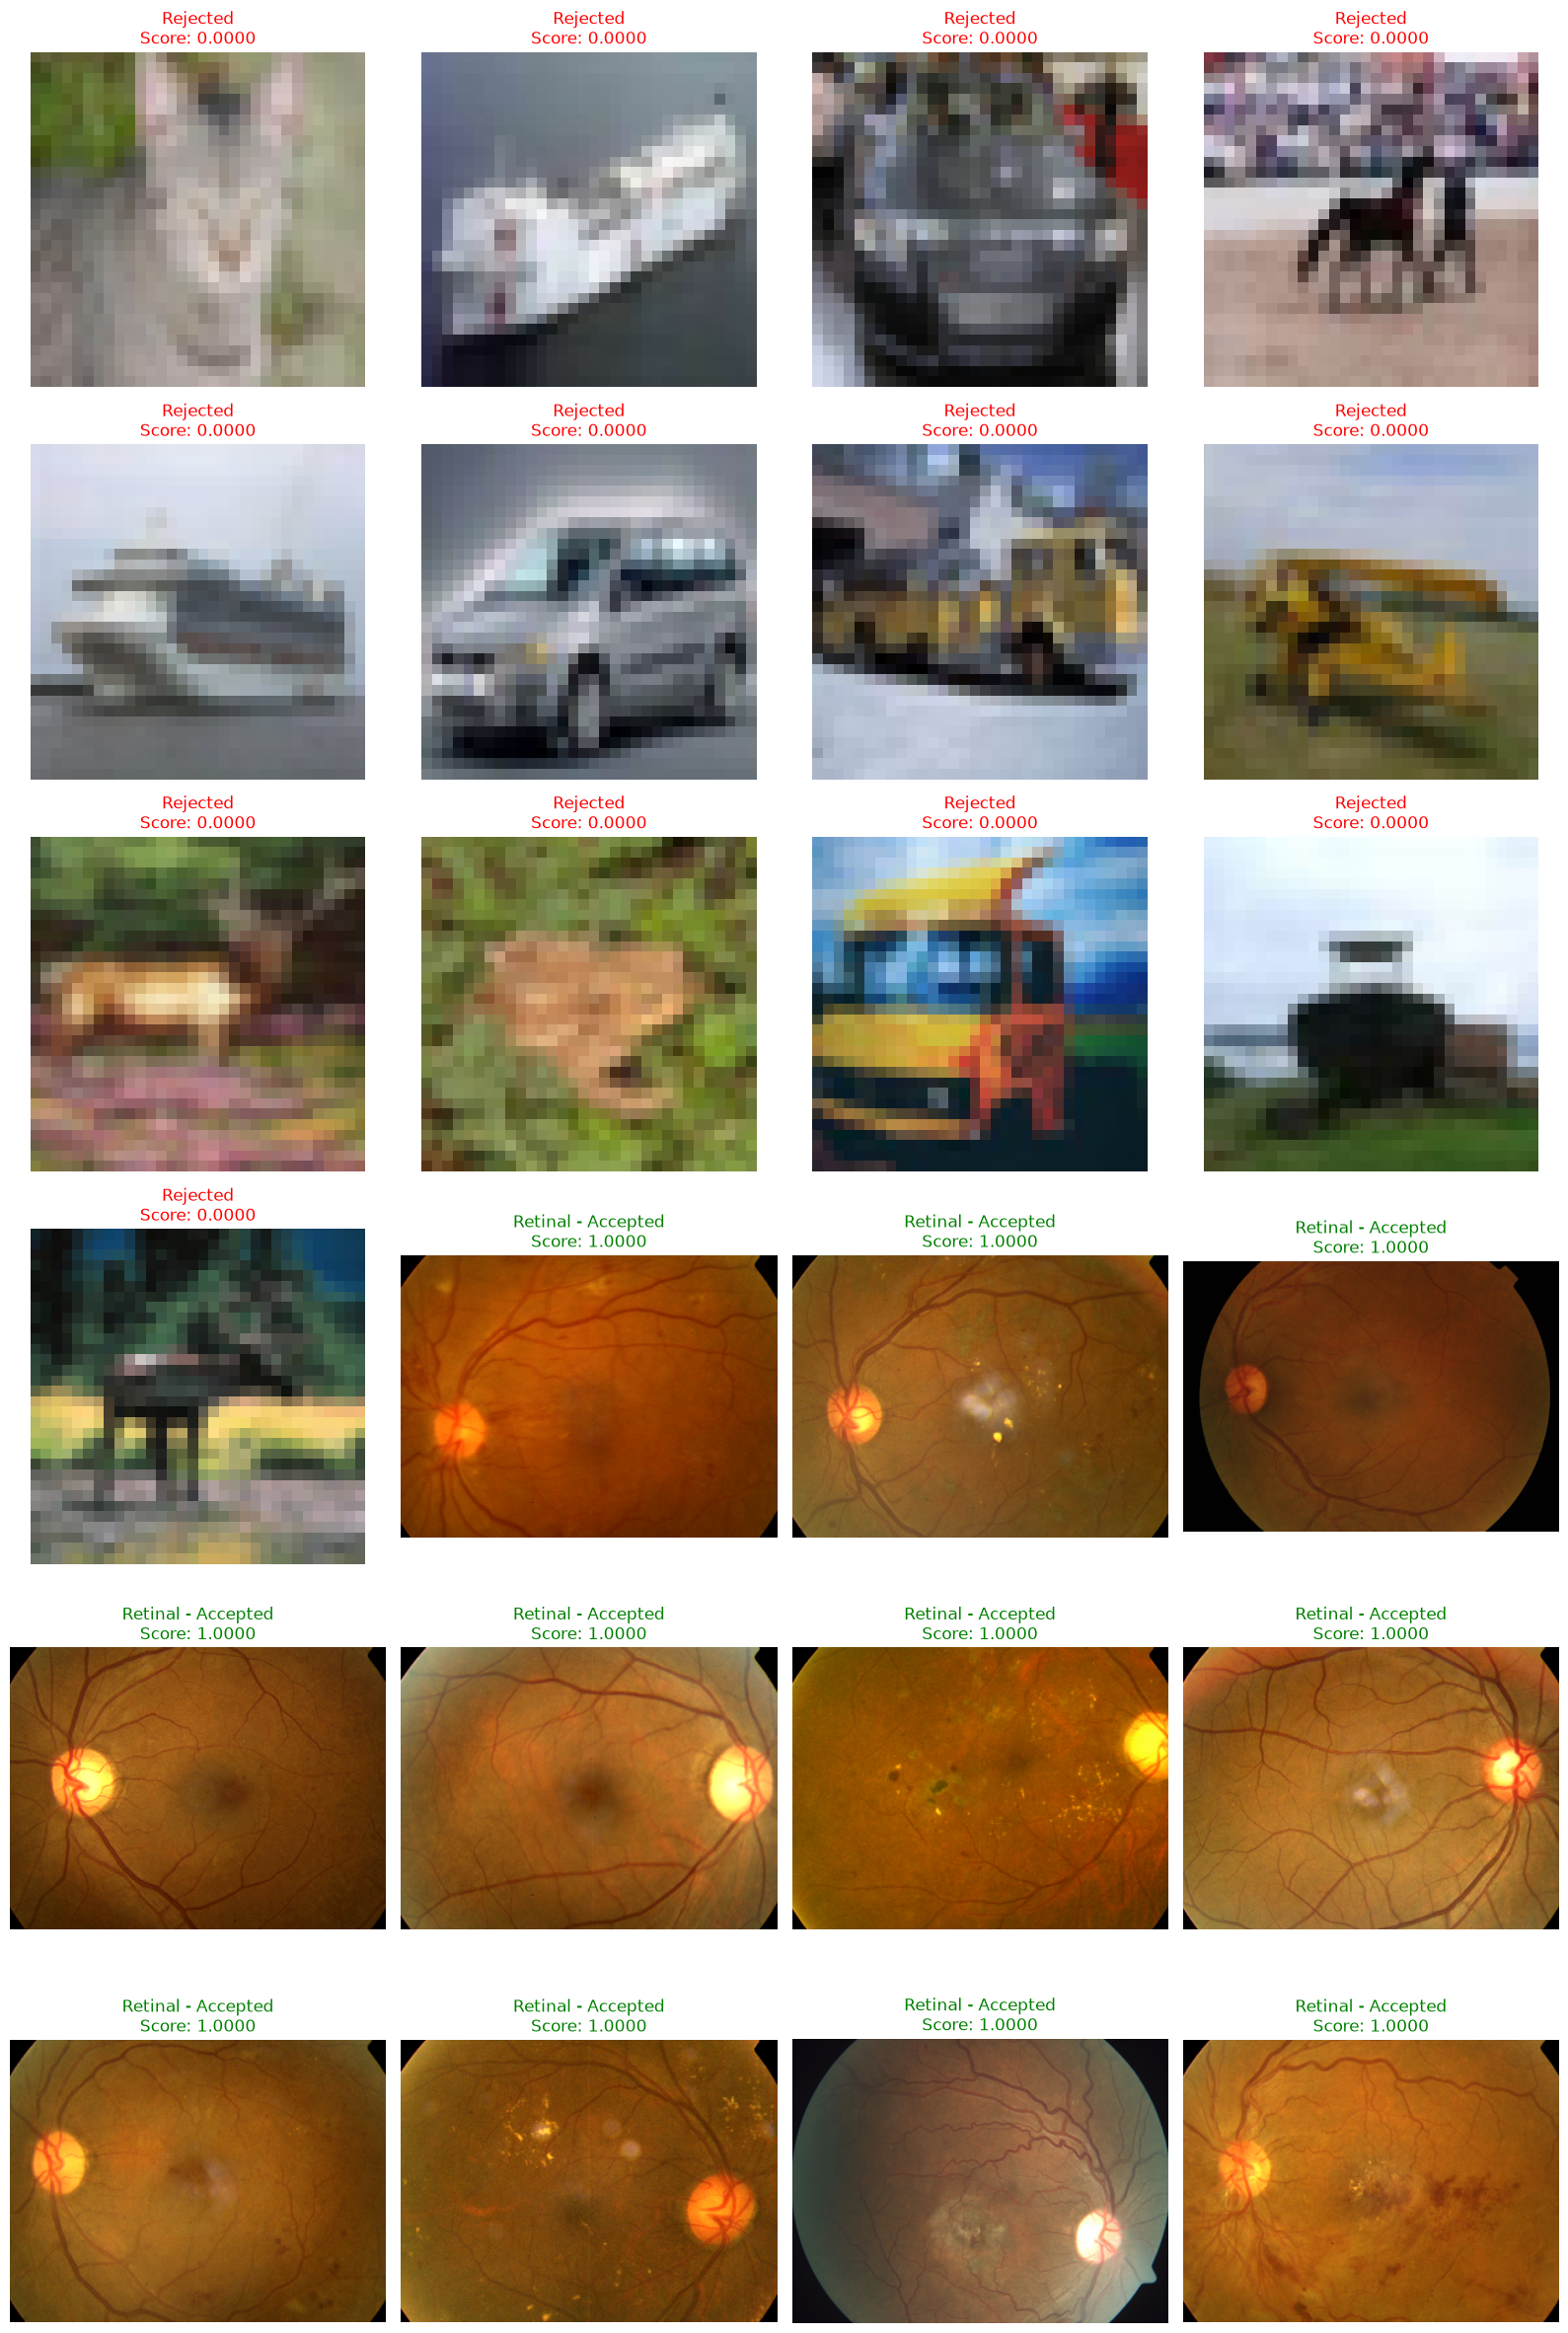

In [32]:
if not manual_images:

    print("No manual test images found.")

else:

    columns = 4

    rows = int(
        np.ceil(len(manual_images) / columns)
    )

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, rows * 4),
        squeeze=False
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, path in zip(
        axes,
        manual_images
    ):

        result = validate_retinal_image(path)

        image = tf.keras.utils.load_img(path)

        accepted = result["is_retinal"]

        status = (
            "Retinal - Accepted"
            if accepted
            else "Rejected"
        )

        ax.imshow(image)

        ax.set_title(
            f"{status}\n"
            f"Score: {result['retinal_score']:.4f}",
            color="green" if accepted else "red"
        )

    plt.tight_layout()

    plt.show()

In [24]:
evaluation_summary = {
    "model": "MobileNetV2",
    "threshold": SELECTED_THRESHOLD,
    "test_samples": int(len(y_true)),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "roc_auc": float(auc),
    "false_acceptance_rate": float(far),
    "false_rejection_rate": float(frr),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

with open(
    RESULTS_DIR / "evaluation_summary.json",
    "w"
) as file:

    json.dump(
        evaluation_summary,
        file,
        indent=4
    )

threshold_df.to_csv(
    RESULTS_DIR / "threshold_comparison.csv",
    index=False
)

source_summary.to_csv(
    RESULTS_DIR / "source_wise_results.csv"
)

if not manual_results_df.empty:

    manual_results_df.to_csv(
        RESULTS_DIR / "manual_test_results.csv",
        index=False
    )

print("Evaluation results saved successfully.")

print(
    json.dumps(
        evaluation_summary,
        indent=4
    )
)

Evaluation results saved successfully.
{
    "model": "MobileNetV2",
    "threshold": 0.99,
    "test_samples": 600,
    "accuracy": 1.0,
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0,
    "roc_auc": 1.0,
    "false_acceptance_rate": 0.0,
    "false_rejection_rate": 0.0,
    "true_negatives": 300,
    "false_positives": 0,
    "false_negatives": 0,
    "true_positives": 300
}


In [33]:
MANUAL_TEST_DIR = VALIDATOR_DIR / "manual_test"

manual_records = []

valid_extensions = {
    ".jpg", ".jpeg", ".png"
}

for class_name, actual_label in [
    ("retinal", 1),
    ("non_retinal", 0)
]:

    class_dir = MANUAL_TEST_DIR / class_name

    for path in sorted(class_dir.rglob("*")):

        if (
            not path.is_file()
            or path.suffix.lower()
            not in valid_extensions
        ):
            continue

        try:

            result = validate_retinal_image(path)

            predicted_label = int(
                result["is_retinal"]
            )

            manual_records.append({
                "Image": path.name,
                "Actual_Label": actual_label,
                "Predicted_Label": predicted_label,
                "Retinal_Score": result["retinal_score"],
                "Status": (
                    "Accepted"
                    if predicted_label == 1
                    else "Rejected"
                ),
                "Correct": (
                    actual_label == predicted_label
                )
            })

        except Exception as error:

            print(
                f"Error processing {path.name}: {error}"
            )

manual_results_df = pd.DataFrame(
    manual_records
)

manual_results_df

,Image,Actual_Label,Predicted_Label,Retinal_Score,Status,Correct
0,0af080866c24.png,1,1,9.999995e-01,Accepted,True
1,0ecaf177e85f.png,1,1,1.000000e+00,Accepted,True
2,0edc0c33e929.png,1,1,1.000000e+00,Accepted,True
3,0f1613975335.png,1,1,9.999999e-01,Accepted,True
4,0f1a967313c3.png,1,1,1.000000e+00,Accepted,True
5,0fb31b7aef5f.png,1,1,1.000000e+00,Accepted,True
6,1a6b7f58d488.png,1,1,1.000000e+00,Accepted,True
7,1b1522622a53.png,1,1,1.000000e+00,Accepted,True
8,1c6e15aeb154.png,1,1,1.000000e+00,Accepted,True
9,1ca7ecbd29fc.png,1,1,1.000000e+00,Accepted,True


In [34]:
if manual_results_df.empty:

    print("No test images found.")

else:

    actual = manual_results_df[
        "Actual_Label"
    ].to_numpy()

    predicted = manual_results_df[
        "Predicted_Label"
    ].to_numpy()

    tn_m, fp_m, fn_m, tp_m = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    manual_accuracy = accuracy_score(
        actual,
        predicted
    )

    manual_far = (
        fp_m / (fp_m + tn_m)
        if fp_m + tn_m > 0
        else np.nan
    )

    manual_frr = (
        fn_m / (fn_m + tp_m)
        if fn_m + tp_m > 0
        else np.nan
    )

    print("=" * 55)
    print("REAL-WORLD VALIDATOR TEST RESULTS")
    print("=" * 55)

    print("Total Images:", len(actual))

    print("Retinal Images:", sum(actual == 1))

    print("Non-Retinal Images:", sum(actual == 0))

    print(f"\nAccuracy: {manual_accuracy:.2%}")

    print("True Negatives:", tn_m)

    print("False Positives:", fp_m)

    print("False Negatives:", fn_m)

    print("True Positives:", tp_m)

    print(f"\nFalse Acceptance Rate: {manual_far:.2%}")

    print(f"False Rejection Rate: {manual_frr:.2%}")

    print("=" * 55)

    manual_results_df.to_csv(
        RESULTS_DIR / "real_world_test_results.csv",
        index=False
    )

REAL-WORLD VALIDATOR TEST RESULTS
Total Images: 24
Retinal Images: 11
Non-Retinal Images: 13

Accuracy: 100.00%
True Negatives: 13
False Positives: 0
False Negatives: 0
True Positives: 11

False Acceptance Rate: 0.00%
False Rejection Rate: 0.00%


In [35]:
if not manual_results_df.empty:

    incorrect = manual_results_df[
        manual_results_df["Correct"] == False
    ]

    print(
        "Incorrect Predictions:",
        len(incorrect)
    )

    if incorrect.empty:

        print("All processed test images classified correctly.")

    else:

        display(incorrect)

Incorrect Predictions: 0
All processed test images classified correctly.
